### Learning Hugging face Text Classification

* Resource Notebook: https://www.learnhuggingface.com/notebooks/hugging_face_text_classification_tutorial

* Setup steps: https://www.learnhuggingface.com/extras/setup

### 2. Import necessary libraries

In [1]:
import transformers
import datasets

In [2]:
# import dependencies
try:
  import datasets, evaluate, accelerate
  import gradio as gr
except ModuleNotFoundError:
  !pip install -U datasets evaluate accelerate gradio
  import datasets, evaluate, accelerate
  import gradio as gr

import random

import numpy as np
import pandas as pd

import torch
import transformers

print(f"Using transformers version: {transformers.__version__}")
print(f"Using torch version: {torch.__version__}")
print(f"Using datasets version: {datasets.__version__}")

Using transformers version: 5.17.0
Using torch version: 2.11.0
Using datasets version: 5.0.1


In [3]:
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

print(device)

mps


## 3. Getting a dataset

Building food not food text classification model: need food not food text dataset.

In [4]:
from datasets import load_dataset

dataset = load_dataset("mrdbourke/learn_hf_food_not_food_image_captions")
dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 250
    })
})

In [5]:
# what fetures are there
dataset.column_names

{'train': ['text', 'label']}

In [6]:
# Access the training split
dataset["train"]

Dataset({
    features: ['text', 'label'],
    num_rows: 250
})

In [7]:
dataset["train"][0]

{'text': 'Creamy cauliflower curry with garlic naan, featuring tender cauliflower in a rich sauce with cream and spices, served with garlic naan bread.',
 'label': 'food'}

### Inspect random samples

In [8]:
import random

random_indexs = random.sample(range(len(dataset["train"])), 5)
print(random_indexs)

random_samples = dataset["train"][random_indexs]

print(f"[INFO] Random samples from dataset:\n")
for text, label in zip(random_samples["text"], random_samples["label"]):
  print(f"Text: {text} | Label: {label}")

[118, 29, 162, 241, 15]
[INFO] Random samples from dataset:

Text: A bowl of sliced bananas with a sprinkle of cocoa powder and a side of peanut butter | Label: food
Text: Hammock swaying between two trees | Label: not_food
Text: A colorful bowl of mixed carrots, including orange and purple. | Label: food
Text: Close-up of a sushi roll with avocado, cucumber, and salmon. | Label: food
Text: Reading a book on the couch, a woman has a cat curled up beside her | Label: not_food


In [9]:
# Get unique label values
dataset["train"].unique("label")

['food', 'not_food']

In [10]:
# Check the count of each label
from collections import Counter

Counter(dataset["train"]["label"])

Counter({'food': 125, 'not_food': 125})

In [11]:
# Turn our dataset into a DataFrame and get a random sample
food_not_food_df = pd.DataFrame(dataset["train"])
food_not_food_df.sample(7)

,text,label
92,Yoga mat rolled up and ready in a corner,not_food
105,Set of measuring spoons hung on a rack,not_food
193,A bowl of sliced dragon fruit with a sprinkle ...,food
95,Set of keys hanging on a hook by the door,not_food
19,White ceramic vase holding fresh flowers,not_food
106,Set of potholders stored in a drawer,not_food
197,"Pizza with a stuffed crust, oozing with cheese",food


In [12]:
food_not_food_df["label"].value_counts()

label
food        125
not_food    125
Name: count, dtype: int64

## 4. Preparing data for text classification

We want to:

1. Tokenize our text - turn our text into numbers (this goes for labels as well).
2. Create a train/test split - want to train our model on the training split and want to evaluate our model on the test split.

In [13]:
# Create a mapping for labels to numeric value
id2label = {0: "not_food", 1: "food"}
label2id = {"not_food": 0, "food": 1}

print(id2label)
print(label2id)

{0: 'not_food', 1: 'food'}
{'not_food': 0, 'food': 1}


In [14]:
# Create mappings programmatically from dataset
id2label = {idx: label for idx, label in enumerate(dataset["train"].unique("label")[::-1])}
label2id = {label: idx for idx, label in id2label.items()}
print(id2label)
print(label2id)

{0: 'not_food', 1: 'food'}
{'not_food': 0, 'food': 1}


In [15]:
id2label = {}
for idx, label in enumerate(dataset["train"].unique("label")[::-1]):
  print(idx, label)
  id2label[idx] = label

0 not_food
1 food


In [16]:
# Turn labels into 0 or 1
def map_labels_to_number(example):
  example["label"] = label2id[example["label"]]
  return example

example_sample = {"text": "This is a sentence about my favourite food: honey", "label": "food"}

# Test our function
map_labels_to_number(example_sample)

{'text': 'This is a sentence about my favourite food: honey', 'label': 1}

In [17]:
# Map our dataset labels to number (the whole thing)
# doing with datasets.map() - https://huggingface.co/docs/datasets/en/process#map
dataset = dataset["train"].map(map_labels_to_number)
dataset[:5]

{'text': ['Creamy cauliflower curry with garlic naan, featuring tender cauliflower in a rich sauce with cream and spices, served with garlic naan bread.',
  'Set of books stacked on a desk',
  'Watching TV together, a family has their dog stretched out on the floor',
  'Wooden dresser with a mirror reflecting the room',
  'Lawn mower stored in a shed'],
 'label': [1, 0, 0, 0, 0]}

In [18]:
# Shuffle data and look at 5 more random samples
dataset.shuffle()[:5]

{'text': ['A slice of pizza with a spicy buffalo chicken topping and a drizzle of ranch dressing',
  'Pizza with a white sauce base, topped with spinach and artichokes',
  'Black leather couch adding elegance to a living room',
  'Garage door with a remote control ready for use',
  'Set of board games stacked on a shelf'],
 'label': [1, 1, 0, 0, 0]}

### Split the dataset into training and test sets

* Train set = mdoel will learn patterns on this dataset
* Validation set (optional) = we can tune our model's hyperparameters in this set
* Test set = model will evaluate patterns on this dataset.

We can split our dataset using `datasets.Dataset.train_test_split`. - https://huggingface.co/docs/datasets/en/process#split

In [19]:
# Split our dataset into train/test splits
dataset = dataset.train_test_split(test_size=0.2, seed=42)
dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 200
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 50
    })
})

In [20]:
random_idx_train = random.randint(0, len(dataset["train"]))
random_sample_train = dataset["train"][random_idx_train]
random_sample_train

{'text': 'Parsnips in a bowl, sprinkled with thyme and served with a side of honey for a tasty, unique snack.',
 'label': 1}

In [21]:
random_idx_test = random.randint(0, len(dataset["test"]))
random_sample_test = dataset["test"][random_idx_test]
random_sample_test

{'text': 'Vibrant red curry with tofu and bell peppers, featuring tofu and sweet bell peppers in a rich coconut milk sauce.',
 'label': 1}

In [22]:
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

print(device)

mps


### Tokenizing our text data (turning text into numbers)

The premise of tokenization is to turn words into numbers.

The `transformers` library has in-built support for Hugging Face `tokenizers`.

And the class `transformers.Autotokenizer` helps pair a model to a tokenizer.

* Model/Tokenizer we're going to use: https://huggingface.co/distilbert/distilbert-base-uncased
* Models are often paired with tokenizers
* Tokenizer = turn text into numbers
* Model = finds patterns in those numbers.

In [23]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(pretrained_model_name_or_path="distilbert/distilbert-base-uncased",
                                         use_fast=True) # use the fast implementation (on by default, note: this requires rust installed)
tokenizer

BertTokenizer(name_or_path='distilbert/distilbert-base-uncased', vocab_size=30522, model_max_length=512, padding_side='right', truncation_side='right', special_tokens={'unk_token': '[UNK]', 'sep_token': '[SEP]', 'pad_token': '[PAD]', 'cls_token': '[CLS]', 'mask_token': '[MASK]'}, added_tokens_decoder={
	0: AddedToken("[PAD]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	100: AddedToken("[UNK]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	101: AddedToken("[CLS]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	102: AddedToken("[SEP]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	103: AddedToken("[MASK]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
})

In [24]:
# Test out the tokenizer
tokenizer("I love pizza")

{'input_ids': [101, 1045, 2293, 10733, 102], 'token_type_ids': [0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1]}

* `input_ids` = our text turned into numbers
* `attention_mask` = whether or not to pay attention to certain tokens (1 = pay attention, 0 = no don't pay attention)

In [25]:
 # Get the length of our tokenizer vocab
length_of_tokenizer_vocab = len(tokenizer.vocab)
print(f"[INFO] Number of items in our tokenizer vocab: {length_of_tokenizer_vocab}")

# Get the maximum sequence length the tokenizer can handle
max_tokenizer_input_sequence_length = tokenizer.model_max_length
print(f"[INFO] Max tokenizer input sequence length: {max_tokenizer_input_sequence_length}")

[INFO] Number of items in our tokenizer vocab: 30522
[INFO] Max tokenizer input sequence length: 512


In [26]:
tokenizer("aakash")

{'input_ids': [101, 9779, 13716, 2232, 102], 'token_type_ids': [0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1]}

In [27]:
tokenizer.convert_ids_to_tokens(tokenizer("aakash").input_ids)

['[CLS]', 'aa', '##kas', '##h', '[SEP]']

In [28]:
# Try to tokenize an emoji
tokenizer.convert_ids_to_tokens(tokenizer("🍕").input_ids)

['[CLS]', '[UNK]', '[SEP]']

In [29]:
# Get the first 5 items in the tokenizer vocab
sorted(tokenizer.vocab.items())[:5]

[('!', 999), ('"', 1000), ('#', 1001), ('##!', 29612), ('##"', 29613)]

In [30]:
import random

random.sample(sorted(tokenizer.vocab.items()), k=5)

[('paths', 10425),
 ('[unused668]', 673),
 ('dell', 12418),
 ('variants', 10176),
 ('afraid', 4452)]

### Making a preprocessing function to tokenize text

Want to make it easy to go from sample -> tokenized_sample.

In [31]:
def tokenize_text(examples): 
    """
    Tokenize given example text and return the tokenized text.
    """
    return tokenizer(examples["text"],
                    padding=True, # pad short sequences to longest sequence length in batch (e.g. if sample length = 100, sample will be padded to 512 or longest sample in batch)
                    truncation=True) # truncate long sequences to maximum length the model can handle (e.g. if sample length = 1000, model length = 512, sample will be shortened to 512)

In [32]:
example_sample_2 = {"text": "I love pizza", "label": 1}

# Test the function
tokenize_text(example_sample_2)

{'input_ids': [101, 1045, 2293, 10733, 102], 'token_type_ids': [0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1]}

In [33]:
long_text = "I love pizza " * 1000
len(long_text)

13000

In [34]:
tokenized_long_text = tokenize_text({"text": long_text, "label": 1})
len(tokenized_long_text["input_ids"])

512

In [35]:
# Map our tokenize text function to the dataset
tokenized_dataset = dataset.map(function=tokenize_text,
                               batched=True, # set batched=True to tokenize across batches of samples at a time rather than one at a time
                               batch_size=1000)

tokenized_dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 200
    })
    test: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 50
    })
})

**Note: ** In machine learning, it is often faster to do things in batches rather than one at a time due to leveraging computer hardware parallelization. documentation: https://huggingface.co/docs/datasets/v2.20.0/en/package_reference/main_classes#datasets.Dataset.map

In [36]:
tokenizer.all_special_tokens

['[UNK]', '[SEP]', '[PAD]', '[CLS]', '[MASK]']

In [37]:
tokenizer.all_special_ids

[100, 102, 0, 101, 103]

In [38]:
# Get two samples from the tokenized datasets
train_tokenized_sample = tokenized_dataset["train"][0]
test_tokenized_sample = tokenized_dataset["test"][0]

for key in train_tokenized_sample.keys():
    print(f"[INFO] Key: {key}")
    print(f"Train sample: {train_tokenized_sample[key]}")
    print(f"Test sample: {test_tokenized_sample[key]}")
    print()

[INFO] Key: text
Train sample: Set of headphones placed on a desk
Test sample: A slice of pepperoni pizza with a layer of melted cheese

[INFO] Key: label
Train sample: 0
Test sample: 1

[INFO] Key: input_ids
Train sample: [101, 2275, 1997, 2132, 19093, 2872, 2006, 1037, 4624, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Test sample: [101, 1037, 14704, 1997, 11565, 10698, 10733, 2007, 1037, 6741, 1997, 12501, 8808, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

[INFO] Key: token_type_ids
Train sample: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Test sample: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

[INFO] Key: attention_mask
Train sample: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Test sample: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0

### Tokenization takeaways

1. Tokenizers = turn data into numbers (e.g. text -> map to number)
2. Many models are out there and have different tokenizers, Hugging Face's `Auto` (e.g. `AutoTokenizer`, `AutoProcessor`, `AutoModel` etc help to match rokenizers to models)
3. Tokenization can happen in parallel using `map` and batched functions.

## Setting up an evaluation metric

We use the evaluation metric to get a numerical idea of how our model is performimg.

Some common evaluation metrics for classification:

- Accuracy (how many examples out of 100, did you get correct?)
- Precision
- Recall
- F1 Score

Evaluation metric is important because some projects may have an evaluation threshold you need to fulfill.
Some places for evaluation metrics:

- Scikit-learn documentation: https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics
- Hugging Face evaluate: https://huggingface.co/docs/evaluate/en/index


In [39]:
import evaluate
import numpy as np
from typing import Tuple

accuracy_metrics = evaluate.load("accuracy")

def compute_accuracy(predictions_and_labels: Tuple[np.array, np.array]):
    """
    Computes the accuracy of a model by comparing the predictions and labels.
    """
    predictions, labels = predictions_and_labels

    return accuracy_metrics.compute(predictions=predictions, references=labels)

In [40]:
# Example predictions and accuracy score
example_preds_all_correct = np.array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])
example_preds_one_incorrect = np.array([0, 0, 0, 0, 1, 0, 0, 0, 0, 0])
example_labels = np.array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

# Test the function
print(f"Accuracy when all predicitons are correct: {compute_accuracy((example_preds_all_correct, example_labels))}")
print(f"Accuracy when one prediciton is incorrect: {compute_accuracy((example_preds_one_incorrect, example_labels))}")


Accuracy when all predicitons are correct: {'accuracy': 1.0}
Accuracy when one prediciton is incorrect: {'accuracy': 0.9}


## Setting up a model for training

* We're going to be using transfer learning.
* Transfer learning is a powerful technique unique to deep learning models that enables us to use the patterns one model has learned, on another problem for our own problem.

Workflow for training: 

1. Create and preprocess data
2. Define the model we'd like to use for our problem: https://huggingface.co/models or https://huggingface.co/docs/transformers/main/en/tasks/sequence_classification
3. Define training arguments for training our model `transformers.TrainingArguments`
   * These are also known as "hyperparameters" = settings on your model that you can adjust
   * Parameters = weights/patterns in the model that get updated automatically
4. Pass `TrainingArguments` to an instance of `transformers.Trainer`
5. Train the model by calling  `Trainer.train()`
6. Save the model (to our local machine or to Hugging Face Hub)
7. Evaluate the trained model by making and inspecting predictions on the test data (and our own custom data)
8. Turn the model into a shareable demo.

In [41]:
label2id

{'not_food': 0, 'food': 1}

In [42]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    pretrained_model_name_or_path="distilbert/distilbert-base-uncased",
    num_labels=2, # classifiy into food/not_food
    id2label=id2label,
    label2id=label2id    
)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [43]:
model

DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
          (ffn): FFN(
            (dropout): Dropout(p=0.1, inplace=False)


Our model is comprised of the following parts:

1. `embeddings` - embeddings are a form of learned representation of tokens. So if tokens are a direct mapping from token to number, embeddings are a learned vector representation.
2. `transformer` - our model architecture backbone, this has discovered patterns/relationships in the embeddings.
3. `classifier` - we need to customize this layer to suit our problem.

Note: If you get input errors from passing a sample to a model, make sure the sample you pass to your model is formatting in the same way you model was trained on. For example, if your model used a specific tokenizer, make sure to tokenize your text before passing it to the model.

In [44]:
# Try and make a prediction with the loaded model (this will error)",
#model(**tokenized_dataset["train"][0])

### Count the parameters in our model

Weights/parameters = small numeric opportunities for a model to learn patterns in data.

In [45]:
def count_params(model):
    """
    Count the parameters of a PyTorch model.
    """
    trainable_parameters = sum(param.numel() for param in model.parameters() if param.requires_grad) 
    total_parameters = sum(param.numel() for param in model.parameters())

    return{"trainable_parameters": trainable_parameters, "trainable_paramters": total_parameters}

count_params(model)

{'trainable_parameters': 66955010, 'trainable_paramters': 66955010}

Our model has around 67M parameters and **all** of them are trainable.

Note:
* Generally, the more parameters a model has, the more capacity it has to learn.
* For comparison, models such as Llama 3 8B has 8 billion parameters.
* However, a smaller model can perform well with specific data.

### Create a directory for saving models

In [46]:
# Create model output directory
from pathlib import Path

# Create models dir
models_dir = Path("models")
models_dir.mkdir(exist_ok=True)

# Create model save name
model_save_name = "hf_food_not_food_text_classifier-distilbert-base-uncased"

# Create model save path
model_save_dir = Path(models_dir, model_save_name)

model_save_dir

PosixPath('models/hf_food_not_food_text_classifier-distilbert-base-uncased')

### Setting up training arguments (hyperparameters) with TrainingArguments

1. ✅Create and preprocess data
2. ✅Define the model we'd like to use for our problem: https://huggingface.co/models or https://huggingface.co/docs/transformers/main/en/tasks/sequence_classification
3. Define training arguments for training our model `transformers.TrainingArguments`
   * These are also known as "hyperparameters" = settings on your model that you can adjust
   * Parameters = weights/patterns in the model that get updated automatically
4. Pass `TrainingArguments` to an instance of `transformers.Trainer`
5. Train the model by calling  `Trainer.train()`
6. Save the model (to our local machine or to Hugging Face Hub)
7. Evaluate the trained model by making and inspecting predictions on the test data (and our own custom data)
8. Turn the model into a shareable demo.

In [47]:
from transformers import TrainingArguments

print(f"[INFO] Saving model checkpoints: {model_save_dir}")

BATCH_SIZE=32

# Create training arguments
training_args = TrainingArguments(
    output_dir=model_save_dir,
    learning_rate=0.0001,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    num_train_epochs=10,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=3,
    use_cpu=False,
    seed=42,
    load_best_model_at_end=True,
    logging_strategy="epoch",
    report_to="none",
  # hub token= "YOUR_TOKEN_HERE_hf-aifjiuefiwenr23gisdf4r4....",
  # push_to_hub=True # if you want your model to save directly to the Hugging Face after training
    hub_private_repo=False # when uploading to Hugging Face Hub, do you want your repo to be public or private? (default:public)
)

[INFO] Saving model checkpoints: models/hf_food_not_food_text_classifier-distilbert-base-uncased


In [48]:
# training_args

### Setting up an instance of Trainer


1. ✅Create and preprocess data
2. ✅Define the model we'd like to use for our problem: https://huggingface.co/models or https://huggingface.co/docs/transformers/main/en/tasks/sequence_classification
3. ✅Define training arguments for training our model `transformers.TrainingArguments`
   * These are also known as "hyperparameters" = settings on your model that you can adjust
   * Parameters = weights/patterns in the model that get updated automatically
4. Pass `TrainingArguments` to an instance of `transformers.Trainer`
5. Train the model by calling  `Trainer.train()`
6. Save the model (to our local machine or to Hugging Face Hub)
7. Evaluate the trained model by making and inspecting predictions on the test data (and our own custom data)
8. Turn the model into a shareable demo.

* Docs for `transformers.Trainer`: https://huggingface.co/docs/transformers/v4.43.3/en/main_classes/trainer#trainer

In [49]:
import evaluate
import numpy as np
from typing import Tuple

accuracy_metrics = evaluate.load("accuracy")

def compute_accuracy(predictions_and_labels: Tuple[np.array, np.array]):
    """
    Computes the accuracy of a model by comparing the predictions and labels.
    """
    predictions, labels = predictions_and_labels

    if len(predictions.shape) >= 2:
        predictions=np.argmax(predictions, axis=1)
    
    return accuracy_metrics.compute(predictions=predictions, references=labels)

In [50]:
from transformers import Trainer

# Setup Trainer instance
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["test"],
    processing_class=tokenizer, # Trainer now uses processing_class
    compute_metrics=compute_accuracy
)

trainer

### Train the model by calling `Trainer.train()`


1. ✅Create and preprocess data
2. ✅Define the model we'd like to use for our problem: https://huggingface.co/models or https://huggingface.co/docs/transformers/main/en/tasks/sequence_classification
3. ✅Define training arguments for training our model `transformers.TrainingArguments`
   * These are also known as "hyperparameters" = settings on your model that you can adjust
   * Parameters = weights/patterns in the model that get updated automatically
4. ✅Pass `TrainingArguments` to an instance of `transformers.Trainer`
5. Train the model by calling  `Trainer.train()`
6. Save the model (to our local machine or to Hugging Face Hub)
7. Evaluate the trained model by making and inspecting predictions on the test data (and our own custom data)
8. Turn the model into a shareable demo.

In [51]:
input_predictions = np.array([[-2.669477, 2.6879058]])
input_references = np.array([0])

# need to get the maximum value from the model output (the index) as this is the "most likely" label according to the model
# see np.argmax docs: 
if len(input_predictions.shape) >= 2:
    input_predictions = np.argmax(input_predictions, axis=1)

input_predictions

array([1])

In [52]:
compute_accuracy(predictions_and_labels=(input_predictions, input_references))

{'accuracy': 0.0}

In [53]:
results = trainer.train()

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy
1,0.486526,0.165484,1.000000
2,0.119542,0.016196,1.000000
3,0.011576,0.019338,0.980000
4,0.002677,0.005370,1.000000
5,0.001377,0.001774,1.000000
6,0.000932,0.001090,1.000000
7,0.000742,0.000880,1.000000
8,0.000666,0.000796,1.000000
9,0.000631,0.000760,1.000000
10,0.000664,0.000750,1.000000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [54]:
results.metrics

{'train_runtime': 28.3159,
 'train_samples_per_second': 70.632,
 'train_steps_per_second': 2.472,
 'total_flos': 18110777160000.0,
 'train_loss': 0.06253335650877229,
 'epoch': 10.0}

In [55]:
# Inspect training metrics
for key, value in results.metrics.items():
    print(f"{key} : {value}")

train_runtime : 28.3159
train_samples_per_second : 70.632
train_steps_per_second : 2.472
total_flos : 18110777160000.0
train_loss : 0.06253335650877229
epoch : 10.0


### Save the model for later use

> **Note:** If you are saving a model to Google Colab, note that it will disappear from your Colab instance when it disconnects.

In [56]:
# Save model
print(f"[INFO] Saving model to {model_save_dir}")
trainer.save_model(output_dir=model_save_dir)

[INFO] Saving model to models/hf_food_not_food_text_classifier-distilbert-base-uncased


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

### Inspect the model training metrics

In [57]:
# Get training history
trainer_history_all = trainer.state.log_history
trainer_history_metrics = trainer_history_all[:-1]
trainer_history_training_time = trainer_history_all[-1]

# View the first 3
trainer_history_metrics[:3]

[{'loss': 0.4865255355834961,
  'grad_norm': 2.78940749168396,
  'learning_rate': 9.142857142857143e-05,
  'epoch': 1.0,
  'step': 7},
 {'eval_loss': 0.16548369824886322,
  'eval_accuracy': 1.0,
  'eval_runtime': 0.1498,
  'eval_samples_per_second': 333.691,
  'eval_steps_per_second': 13.348,
  'epoch': 1.0,
  'step': 7},
 {'loss': 0.11954207079751152,
  'grad_norm': 0.39665257930755615,
  'learning_rate': 8.142857142857143e-05,
  'epoch': 2.0,
  'step': 14}]

In [58]:
import pprint

# Extract eval an training metrics
trainer_history_train_set = []
trainer_history_eval_set = []

# Loop through our metrics
for item in trainer_history_metrics:
    item_keys = list(item.keys())
    if any("eval" in item for item in item_keys):
        trainer_history_eval_set.append(item)
    else:
        trainer_history_train_set.append(item)
        
# Show the first two from each
print(f"First item in training set:")
pprint.pprint(trainer_history_train_set[:2])

print(f"First two items in eval epochs:")
pprint.pprint(trainer_history_eval_set[:2])

First item in training set:
[{'epoch': 1.0,
  'grad_norm': 2.78940749168396,
  'learning_rate': 9.142857142857143e-05,
  'loss': 0.4865255355834961,
  'step': 7},
 {'epoch': 2.0,
  'grad_norm': 0.39665257930755615,
  'learning_rate': 8.142857142857143e-05,
  'loss': 0.11954207079751152,
  'step': 14}]
First two items in eval epochs:
[{'epoch': 1.0,
  'eval_accuracy': 1.0,
  'eval_loss': 0.16548369824886322,
  'eval_runtime': 0.1498,
  'eval_samples_per_second': 333.691,
  'eval_steps_per_second': 13.348,
  'step': 7},
 {'epoch': 2.0,
  'eval_accuracy': 1.0,
  'eval_loss': 0.01619560644030571,
  'eval_runtime': 0.1308,
  'eval_samples_per_second': 382.205,
  'eval_steps_per_second': 15.288,
  'step': 14}]


### Taking a look at the loss curves

Loss curves = a good visualization of your model's performance over time.

Ideally, loss curves will trend downwards.

In [59]:
# Create a pandas DataFrame for the training and evaluation metrics
trainer_history_train_df = pd.DataFrame(trainer_history_train_set)
trainer_history_eval_df = pd.DataFrame(trainer_history_eval_set)

trainer_history_train_df.head()

,loss,grad_norm,learning_rate,epoch,step
0,0.486526,2.789407,0.000091,1.0,7
1,0.119542,0.396653,0.000081,2.0,14
2,0.011576,0.079096,0.000071,3.0,21
3,0.002677,0.027684,0.000061,4.0,28
4,0.001377,0.021603,0.000051,5.0,35


In [60]:
trainer_history_eval_df.head()

,eval_loss,eval_accuracy,eval_runtime,eval_samples_per_second,eval_steps_per_second,epoch,step
0,0.165484,1.00,0.1498,333.691,13.348,1.0,7
1,0.016196,1.00,0.1308,382.205,15.288,2.0,14
2,0.019338,0.98,0.1357,368.580,14.743,3.0,21
3,0.005370,1.00,0.0995,502.559,20.102,4.0,28
4,0.001774,1.00,0.1378,362.714,14.509,5.0,35


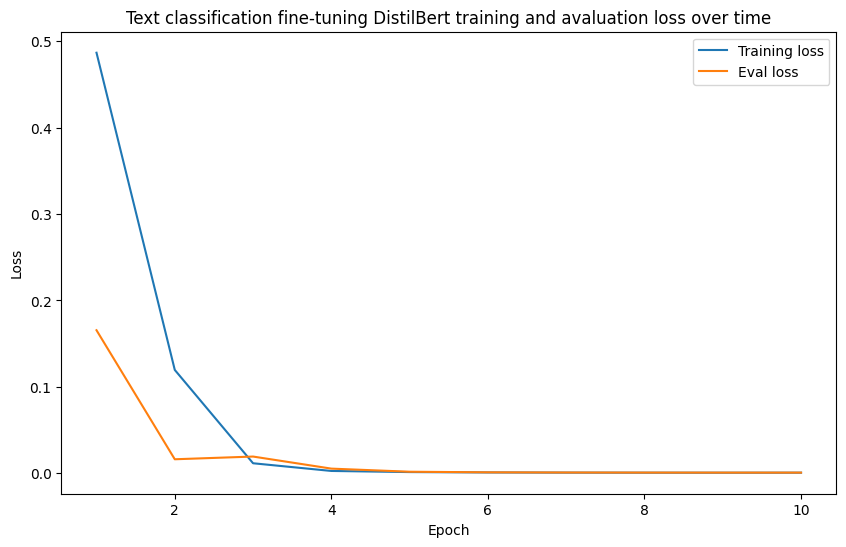

In [61]:
# Plot the loss curves
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(trainer_history_train_df["epoch"], trainer_history_train_df["loss"], label="Training loss")
plt.plot(trainer_history_eval_df["epoch"], trainer_history_eval_df["eval_loss"], label="Eval loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Text classification fine-tuning DistilBert training and avaluation loss over time")
plt.legend()
plt.show()

### Pushing our model to the Hugging Face Hub

To write to Hugging Face:
If on Google Colab: setup "token" with "read and write" access (https://www.learnhuggingface.com/extras/setup#getting-setup-on-google-colab)
If on local machine: setup huggingface-cli (https://huggingface.co/docs/huggingface_hub/en/guides/cli)

To save the Hugging Face Hub, we can use the `Trainer.push_to_hub` method: https://huggingface.co/docs/transformers/v5.17.0/en/main_classes/trainer#transformers.Trainer.push_to_hub

In [62]:
from huggingface_hub import login

login(skip_if_logged_in=False)

In [63]:
from huggingface_hub import whoami

user = whoami()
print("Hugging Face user:", user["name"])

Hugging Face user: aakashdeep1


In [64]:
# Save our model to Hugging Face Hub
model_upload_url = trainer.push_to_hub(
    commit_message="Uploading food not food text classifier model"
    # token="Your_token_here_fb2jhbfub8fknb.." # for hard-coding your token
)
print(f"[INFO] Model successfully uploaded to the Hugging Face Hub with URL: {model_upload_url}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

KeyboardInterrupt: 

## Making and evaluating predictions on the test data

1. ✅Create and preprocess data
2. ✅Define the model we'd like to use for our problem: https://huggingface.co/models or https://huggingface.co/docs/transformers/main/en/tasks/sequence_classification
3. ✅Define training arguments for training our model `transformers.TrainingArguments`
   * These are also known as "hyperparameters" = settings on your model that you can adjust
   * Parameters = weights/patterns in the model that get updated automatically
4. ✅Pass `TrainingArguments` to an instance of `transformers.Trainer`
5. ✅Train the model by calling  `Trainer.train()`
6. ✅Save the model (to our local machine or to Hugging Face Hub)
7. Evaluate the trained model by making and inspecting predictions on the test data (and our own custom data)
8. Turn the model into a shareable demo.

> **Note:** Evaluating a model is just as important as training a model.

We can make predictions on the test data using the `Trainer.predict` method: https://huggingface.co/docs/transformers/v5.17.0/en/main_classes/trainer#transformers.Trainer.predict

In [65]:
tokenized_dataset["train"]

Dataset({
    features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 200
})

In [66]:
tokenized_dataset["test"]

Dataset({
    features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 50
})

In [67]:
# Perform predictions on the test data
predictions_all = trainer.predict(tokenized_dataset["test"])
prediction_values = predictions_all.predictions
prediction_metrics = predictions_all.metrics

print(f"[INFO] Predictions metrics on the test data:")
prediction_metrics

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


[INFO] Predictions metrics on the test data:


{'test_loss': 0.0007500392384827137,
 'test_accuracy': 1.0,
 'test_runtime': 0.622,
 'test_samples_per_second': 80.388,
 'test_steps_per_second': 3.216}

In [68]:
# Model outputs raw logits
predictions_all.predictions[0]

array([-3.841156,  3.704088], dtype=float32)

In [69]:
# Softmax gets all values to be between 0 & 1 and the total of the values sum to 1
# This is what's known as a "predciton probability", as in the model is assigning this value to how "likely" the prediction is given the smaple
torch.softmax(torch.tensor(predictions_all.predictions[0]), dim=0)

tensor([5.2834e-04, 9.9947e-01])

> **Note:** If you want a good evaluation method, make predictions on your entire test dataset, then index on the predictions which are wrong but have high prediction probability. For example, get the top 100-1000 and go through all of the examples where the model's prediction had high probability but was incorrect -> this often leads to great insights into your data. |

In [70]:
0.99943, 0.00057 # Note: these values fon't suggest how "right" the model is, because a model can have a high prediction probabilty but still be wrong

(0.99943, 0.00057)

In [71]:
predictions_all

PredictionOutput(predictions=array([[-3.841156 ,  3.704088 ],
       [ 3.4651253, -4.2066584],
       [-3.8402312,  3.7208447],
       [ 3.5037916, -4.2038784],
       [ 3.4935665, -4.22069  ],
       [-3.845033 ,  3.709375 ],
       [ 3.5004158, -4.198722 ],
       [ 3.5011802, -4.2293825],
       [-3.8443213,  3.710065 ],
       [-3.8349981,  3.7171311],
       [-3.8434339,  3.7050853],
       [-3.8119256,  3.7015207],
       [ 3.4905722, -4.1946554],
       [-3.8396   ,  3.7121506],
       [-3.8336763,  3.7012372],
       [ 3.5020585, -4.2129955],
       [-3.8331382,  3.720982 ],
       [ 3.4386494, -4.161526 ],
       [-3.8405526,  3.7034247],
       [-3.8404694,  3.7139335],
       [-3.827409 ,  3.7164612],
       [-3.8346784,  3.7231836],
       [ 3.488414 , -4.204899 ],
       [ 3.4657326, -4.20383  ],
       [-3.8418212,  3.7161407],
       [-3.8381486,  3.7110415],
       [-3.841411 ,  3.7047195],
       [ 3.472426 , -4.202729 ],
       [-3.8479905,  3.7002435],
       [ 3.498

In [72]:
predictions_all.label_ids

array([1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1,
       0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0,
       1, 1, 1, 1, 0, 1])

## Lets get predicted probabilities and evaluate by hand

In [73]:
# Predicted logits (raw output of the model) -> prediction probabilities with torch.softmax -> predicted labels
import torch
from sklearn.metrics import accuracy_score

# 1. Get prediction probabilities with torch.softmax
pred_probs = torch.softmax(torch.tensor(prediction_values), dim=1)

# 2. Get the predicted labels
pred_labels = torch.argmax(pred_probs, dim=1)

# 3. Get the true label
true_labels = tokenized_dataset["test"]["label"]

# 4. Compute prediction labels to true labels and get the test accuracy
test_accuracy = accuracy_score(y_true=true_labels,
                              y_pred=pred_labels)

print(f"[INFO] Test Accuracy: {test_accuracy*100}")

[INFO] Test Accuracy: 100.0


### Exploring our model's prediction probabilities

It's a very good way to evaluate a model by sorting predictions by prediction probabilities and seeing where the model went wrong.

In [74]:
# Make a DataFrame of test predictions
test_predictions_df = pd.DataFrame({
    "text": dataset["test"]["text"],
    "true_label": true_labels,
    "pred_label": pred_labels,
    "pred_prob": torch.max(pred_probs, dim=1).values
        })

test_predictions_df.head()

,text,true_label,pred_label,pred_prob
0,A slice of pepperoni pizza with a layer of mel...,1,1,0.999472
1,Red brick fireplace with a mantel serving as a...,0,0,0.999534
2,A bowl of sliced bell peppers with a sprinkle ...,1,1,0.999480
3,Set of mugs hanging on a hook,0,0,0.999551
4,Standing floor lamp providing light next to an...,0,0,0.999554


In [75]:
# Show 10 examples with low prediction probability
test_predictions_df.sort_values("pred_prob", ascending=True).head(10)

,text,true_label,pred_label,pred_prob
43,Set of muffin tins stacked together,0,0,0.987338
40,A bowl of cherries with a sprig of mint for ga...,1,1,0.999438
11,A close-up shot of a cheesy pizza slice being ...,1,1,0.999455
42,"Boxes of apples, pears, pineapple, manadrins a...",1,1,0.999459
14,Two handfuls of bananas in a fruit bowl with g...,1,1,0.999466
46,A bowl of sliced kiwi with a sprinkle of sugar...,1,1,0.999471
20,"Pizza with a seafood theme, featuring toppings...",1,1,0.999471
18,Traditional Japanese flavored sushi roll with ...,1,1,0.999471
31,Crunchy sushi roll with tempura flakes or pank...,1,1,0.999472
0,A slice of pepperoni pizza with a layer of mel...,1,1,0.999472


## Making and inspecting predictions on custom text data

In [76]:
local_model_path = "models/hf_food_not_food_text_classifier-distilbert-base-uncased"

hugging_face_model_path = "aakashdeep1/hf_food_not_food_text_classifier-distilbert-base-uncased"

### Discussing ways to make predictions (inference)

* Note: Whenever you hear the word "inference" it means to use a model to make predictions on data.

Two main ways to perfomr inference:

1. **Pipeline mode** - Using `transformers.pipeline` to load our model and perform text classfication. Docs: https://huggingface.co/docs/transformers/en/main_classes/pipelines
2. **PyTorch mode** - Using a combination of `transformers.AutoTokenizer` and `transformers.AutoModelForSequceClassification` and passing each our target model name.

Each mode supports:
1. Predictions one at a time (fast but can be slower with many many samples).
   * Helpful for say a comment system and comments happen sporadically, to predict whether the comment was "spam" or "not spam".
3. Batches of predictions at a time (faster but up to a point, e.g. say you predict 32 samples at a time, this may be way faster than one at a time but if you go to 128 at a time, you may not see many more speedups).
   * Helpful for when you have a large static database or many samples coming in at once.

### Making predictions with pipeline mode

Docs: https://huggingface.co/docs/transformers/v5.17.0/en/main_classes/pipelines#transformers.pipeline

In [77]:
import torch
from transformers import pipeline

# Set the batch size
BATCH_SIZE = 32

# Create an instance of transformers.pipeline
food_not_food_classifier = pipeline(task="text-classification",
                                   model=local_model_path,
                                   device=device,
                                   top_k=1,
                                   batch_size=BATCH_SIZE)
food_not_food_classifier

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

TextClassificationPipeline: {'model': 'DistilBertForSequenceClassification', 'dtype': 'float32', 'device': 'mps', 'input_modalities': 'text'}

In [78]:
test_custom_sentence = "A plate of croissants"
food_not_food_classifier(test_custom_sentence)

[[{'label': 'food', 'score': 0.9991987347602844}]]

In [79]:
test_not_food_sentence = "A yellow tractor driving over a hill"
food_not_food_classifier(test_not_food_sentence)

[[{'label': 'not_food', 'score': 0.9995282888412476}]]

In [82]:
# del pipeline
del food_not_food_classifier

In [83]:
# Use pipeline with a model from Hugging Face
food_not_food_classifier = pipeline(task="text-classification",
                                   model=hugging_face_model_path,
                                   device=device,
                                   top_k=1,
                                   batch_size=BATCH_SIZE)
food_not_food_classifier(test_not_food_sentence)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/351 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/712k [00:00<?, ?B/s]

[[{'label': 'not_food', 'score': 0.9996298551559448}]]

### Making multiple predictions at the same time with batch prediction

In [84]:
# Create a list of sentences to make predictions on
sentences = [
    "I whipped up a fresh batch of code, but it seems to have a syntax error.",
    "We need to marinate these ideas overnight before presenting them to the client.",
    "The new software is definitely a spicy upgrade, taking some time to get used to.",
    "Her social media post was the perfect recipe for a viral sensation.",
    "He served up a rebuttal full of facts, leaving his opponent speechless.",
    "The team needs to simmer down a bit before tackling the next challenge.",
    "The presentation was a delicious blend of humor and information, keeping the audience engaged.",
    "A beautiful array of fake wax foods (shokuhin sampuru) in the front of a Japanese restaurant.",
    "Daniel Bourke is really cool :D",
    "My favoruite food is biltong!"
]

food_not_food_classifier(sentences)

[[{'label': 'food', 'score': 0.5628297328948975}],
 [{'label': 'not_food', 'score': 0.9910300970077515}],
 [{'label': 'food', 'score': 0.9857469797134399}],
 [{'label': 'not_food', 'score': 0.5174534320831299}],
 [{'label': 'not_food', 'score': 0.7163466811180115}],
 [{'label': 'food', 'score': 0.5217928886413574}],
 [{'label': 'food', 'score': 0.9872928857803345}],
 [{'label': 'food', 'score': 0.9993045330047607}],
 [{'label': 'not_food', 'score': 0.9972122311592102}],
 [{'label': 'food', 'score': 0.9956791996955872}]]

In [85]:
food_captions = [
    "Savoring the flavors of a juicy burger on a summer evening.",
    "My favoruite food is biltong!",
    "A delicious slice of pizza straight from the oven.",
    "A beautiful array of fake wax foods (shokuhin sampuru) in the front of a Japanese restaurant.",
    "Freshly baked croissants, straight from the oven.",
    "A steaming bowl of noodles on a cold winter's day.",
    "Grilled to perfection, this steak is a culinary delight.",
    "A vibrant salad, full of fresh vegetables and fruits.",
    "Indulging in a decadent chocolate cake.",
    "A hearty bowl of homemade chicken soup."
]

food_not_food_classifier(food_captions)

[[{'label': 'food', 'score': 0.9994181394577026}],
 [{'label': 'food', 'score': 0.9956791996955872}],
 [{'label': 'food', 'score': 0.9994094371795654}],
 [{'label': 'food', 'score': 0.9993045330047607}],
 [{'label': 'food', 'score': 0.9991287589073181}],
 [{'label': 'food', 'score': 0.9993129968643188}],
 [{'label': 'food', 'score': 0.9993926286697388}],
 [{'label': 'food', 'score': 0.9994239807128906}],
 [{'label': 'food', 'score': 0.9993010759353638}],
 [{'label': 'food', 'score': 0.9994305968284607}]]

In [87]:
not_food_captions = [
    "The sunset over the ocean was breathtaking.",
    "The new software is definitely a spicy upgrade, taking some time to get used to.",
    "The team needs to simmer down a bit before tackling the next challenge.",
    "Her social media post was the perfect recipe for a viral sensation.",
    "He served up a rebuttal full of facts, leaving his opponent speechless.",
    "The presentation was a hit, engaging the audience with humor and information.",
    "The city skyline at night was a sight to behold.",
    "The new book was a real page-turner, keeping me up all night.",
    "The beautiful scenery of the national park was awe-inspiring."
]
food_not_food_classifier(not_food_captions)

[[{'label': 'not_food', 'score': 0.9994887113571167}],
 [{'label': 'food', 'score': 0.9857469797134399}],
 [{'label': 'food', 'score': 0.5217928886413574}],
 [{'label': 'not_food', 'score': 0.5174534320831299}],
 [{'label': 'not_food', 'score': 0.7163466811180115}],
 [{'label': 'food', 'score': 0.9439073204994202}],
 [{'label': 'not_food', 'score': 0.9993336796760559}],
 [{'label': 'not_food', 'score': 0.9993860721588135}],
 [{'label': 'not_food', 'score': 0.9972176551818848}]]

In [88]:
confusing_captions = [
    "The new project was a recipe for disaster.",
    "The team's strategy was a bit of a stretch, like trying to make a soufflé.",
    "The plot twist was the icing on the cake.",
    "The city's traffic was a real meat grinder.",
    "The new policy was a tough pill to swallow.",
    "The company's financials were a recipe for success.",
    "The teacher's explanation was a bit of a sugarcoat.",
    "The politician's speech was a lot of empty calories.",
    "The team's performance was a real mixed bag.",
    "The new idea was a bit of a lemon."
]
food_not_food_classifier(confusing_captions)

[[{'label': 'food', 'score': 0.9642782211303711}],
 [{'label': 'food', 'score': 0.9984710812568665}],
 [{'label': 'food', 'score': 0.9986217021942139}],
 [{'label': 'food', 'score': 0.992422878742218}],
 [{'label': 'not_food', 'score': 0.913585901260376}],
 [{'label': 'food', 'score': 0.9675676226615906}],
 [{'label': 'food', 'score': 0.9764872193336487}],
 [{'label': 'food', 'score': 0.9964191913604736}],
 [{'label': 'food', 'score': 0.776932954788208}],
 [{'label': 'food', 'score': 0.9991810917854309}]]

In [94]:
import time 

# Create 1000 sentences
sentences_1000 = sentences * 100

# Time how long it takes to make predictions on all sentences (one at a time)
print(f'[INFO] Number of sentences: {len(sentences_1000)}')
start_time_one_at_a_time = time.time()
for sentence in sentences_1000:
    # Make a prediction
    food_not_food_classifier(sentence)
end_time_one_at_a_time = time.time()

total_time_one_at_a_time = end_time_one_at_a_time - start_time_one_at_a_time
avg_time_per_pred = total_time_one_at_a_time / len(sentences_1000)
print(f"[INFO] Total time for making predictions on {len(sentences_1000)}: samples one at a time: {total_time_one_at_a_time}s")
print(f"[INFO] Avg time per prediction one at a time: {avg_time_per_pred}s")

[INFO] Number of sentences: 1000
[INFO] Total time for making predictions on 1000: samples one at a time: 13.462388038635254s
[INFO] Avg time per prediction one at a time: 0.013462388038635253s


In [96]:
# Let's now use pipeline in batches
for i in [10, 1000, 1000, 10_000]:
    sentences_big = sentences * i
    print(f"[INFO] Number of sentences: {len(sentences_big)}")

    start_time = time.time()
    # Predict on all sentences in batch mode
    food_not_food_classifier(sentences_big)
    end_time = time.time()

    total_time_per_all_sentences_batch_mode = end_time - start_time
    avg_time_per_sentence_batch_mode = total_time_per_all_sentences_batch_mode / len(sentences_big)

    print(f"[INFO] Inference time for {len(sentences_big)} sentences batch mode: {round(total_time_per_all_sentences_batch_mode, 6)} ")
    print(f"[INFO] Avg inference time per sentence: {round(avg_time_per_sentence_batch_mode, 8)} ")
    print()

[INFO] Number of sentences: 100
[INFO] Inference time for 100 sentences batch mode: 0.587017 
[INFO] Avg inference time per sentence: 0.00587017 

[INFO] Number of sentences: 10000
[INFO] Inference time for 10000 sentences batch mode: 15.698037 
[INFO] Avg inference time per sentence: 0.0015698 

[INFO] Number of sentences: 10000
[INFO] Inference time for 10000 sentences batch mode: 18.151768 
[INFO] Avg inference time per sentence: 0.00181518 

[INFO] Number of sentences: 100000
[INFO] Inference time for 100000 sentences batch mode: 172.821121 
[INFO] Avg inference time per sentence: 0.00172821 



### Making predictions with PyTorch

Steps with PyTorch predictions:

1. Create the tokenizer with `Autotokenizer`.
2. Create the model with `AutoModel` (`AutoModelForSequenceClassification`).
3. Tokenize text with 1
4. Make prediction with 2
5. Format preditction.

In [103]:
from transformers import AutoTokenizer

# Setup the model path
model_path = "aakashdeep1/hf_food_not_food_text_classifier-distilbert-base-uncased"

# Create an example to predict on
sample_food_text = "A delicious photo of a plate of scrambled egg, toast and bacon"

# Prepare the tokenizer
tokenizer =  AutoTokenizer.from_pretrained(pretrained_model_name_or_path=model_path)
inputs = tokenizer(sample_food_text,
                  return_tensors="pt") # "pt" stands for PyTorch
inputs

{'input_ids': tensor([[  101,  1037, 12090,  6302,  1997,  1037,  5127,  1997, 13501,  8288,
          1010, 15174,  1998, 11611,   102]]), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])}

In [104]:
from transformers import AutoModelForSequenceClassification

# Load our text classification model
model = AutoModelForSequenceClassification.from_pretrained(pretrained_model_name_or_path=model_path)
model

b/python3.14/site-packages/jedi/plugins/flask.py", line 20, in wrapper
    return callback(inference_state, import_names, module_context, *args, **kwargs)
  File "/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/jedi/inference/gradual/typeshed.py", line 115, in wrapper
    python_value_set = ValueSet.from_sets(
        func(inference_state, import_names, p, sys_path,)
        for p in parent_module_values
    )
  File "/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/jedi/inference/base_value.py", line 430, in from_sets
    for set_ in sets:
                ^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/jedi/inference/gradual/typeshed.py", line 116, in <genexpr>
    func(inference_state, import_names, p, sys_path,)
    ~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/jedi/inference/imports.py

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
          (ffn): FFN(
            (dropout): Dropout(p=0.1, inplace=False)


In [108]:
import torch

# with torch.no_grad():
with torch.inference_mode():
    outputs = model(**inputs) # "**" means input all of the dictionary keys as named arguments/parameters
    outputs_verbose = model(input_ids=inputs["input_ids"],
                    attention_mask=inputs["attention_mask"])
outputs

SequenceClassifierOutput(loss=None, logits=tensor([[-3.6537,  3.6794]]), hidden_states=None, attentions=None)

In [110]:
outputs_verbose

SequenceClassifierOutput(loss=None, logits=tensor([[-3.6537,  3.6794]]), hidden_states=None, attentions=None)

In [113]:
model.config.id2label

{0: 'not_food', 1: 'food'}

In [116]:
# Convert logits to prediction probability + label
predicted_class_id = outputs.logits.argmax().item()
prediction_probability = torch.softmax(outputs.logits, dim=1).max().item()

print(f"Text: {sample_food_text}")
print(f"Predictied label: {model.config.id2label[predicted_class_id]}")
print(f"Prediction probability: {prediction_probability}")

Text: A delicious photo of a plate of scrambled egg, toast and bacon
Predictied label: food
Prediction probability: 0.999346911907196


In [117]:
food_not_food_classifier(sample_food_text)

[[{'label': 'food', 'score': 0.999346911907196}]]